# Volatility Surface Construction: SVI / SSVI + Neural Smoothing

Greeks, XVA volatilities and stress scenarios all read volatility from a surface, not from individual quotes. Quotes are noisy and sparse, so the surface is a model, and a careless one creates free money on paper and breaks the Monte Carlo engines built on it. This notebook builds the SPY surface three ways, checks each for arbitrage, and derives the local-volatility surface a pricing engine would use.

**What it does.** It builds the SPY implied-volatility surface from today's option chain three ways, checks each for static arbitrage, and derives the local-volatility surface a pricing or XVA engine would use.

1. Raw **SVI**, slice by slice.
2. **SSVI**, one global surface that is arbitrage-free by construction.
3. **SSVI + a neural correction**: a small network that bends SSVI towards the quotes, with arbitrage penalties enforced by automatic differentiation.

**Data.** An SPY option chain snapshot across expiries from one week to two years (Yahoo Finance), with forwards implied from put–call parity and Treasury discounting (FRED).

**Methods.** Gatheral's SVI parameterisation, Gatheral–Jacquier SSVI with a power-law φ, Durrleman's butterfly condition and calendar monotonicity in total variance, and Dupire local volatility from total variance.

The neural correction is a PyTorch MLP with soft no-arbitrage constraints, and held-out strikes measure the out-of-sample error.

**Key output.** In-sample and held-out IV errors per model, arbitrage-violation counts, smiles per expiry, and the implied and local volatility surfaces.

## 1. Why the surface matters and what "arbitrage-free" means

Everything option-related in a risk system (Greeks, FX and rate volatilities in XVA, stress scenarios) reads volatilities from a surface, not from individual quotes. Quotes are noisy and sparse, so the surface is a **model**, and a bad one creates free money on paper: negative butterfly prices or calendar spreads, and imaginary local volatilities that crash Monte Carlo engines.

In total implied variance $w(k,T)=\sigma_{BS}^2(k,T)\,T$, with log-moneyness $k=\ln(K/F_T)$:

- **No calendar arbitrage:** $\partial_T w(k,T)\ge 0$ at every $k$.
- **No butterfly arbitrage** (Durrleman's condition): the implied density is non-negative, which holds when
$$
g(k)=\Big(1-\frac{k\,w'}{2w}\Big)^2-\frac{w'^2}{4}\Big(\frac1w+\frac14\Big)+\frac{w''}{2}\;\ge 0 .
$$
- **Dupire local variance** follows directly: $\sigma_{loc}^2(k,T)=\partial_T w / g(k)$. It is real and positive only if both conditions hold.

| Model | Form | Arbitrage |
|---|---|---|
| **Raw SVI** (Gatheral 2004), per expiry | $w(k)=a+b\big(\rho(k-m)+\sqrt{(k-m)^2+\sigma^2}\big)$ | none guaranteed; slices fitted independently |
| **SSVI** (Gatheral & Jacquier 2014) | $w(k,\theta_T)=\tfrac{\theta_T}{2}\Big(1+\rho\varphi k+\sqrt{(\varphi k+\rho)^2+1-\rho^2}\Big)$, $\varphi(\theta)=\eta\,\theta^{-\gamma}(1+\theta)^{\gamma-1}$ | free of both if $\theta_T$ increases and $\eta(1+|\rho|)\le 2$ |
| **SSVI × neural correction** | $w=w_{SSVI}\cdot e^{\,\epsilon\tanh(\mathrm{NN}(k,T))}$ | penalised: $\mathrm{ReLU}(-g)$ and $\mathrm{ReLU}(-\partial_T w)$ on a dense grid |

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import matplotlib
import yfinance as yf
from scipy import stats
from scipy.optimize import brentq, least_squares

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

UNDERLYING = "SPY"
TARGET_DAYS = [7, 14, 21, 30, 45, 60, 91, 120, 182, 273, 365, 548, 730]
# log-moneyness kept (OTM puts carry most of the skew)
K_RANGE = (-0.35, 0.20)
MAX_REL_SPREAD = 0.25
# every 5th strike per expiry is held out for testing
HOLDOUT_EVERY = 5
# max multiplicative correction of SSVI total variance (±30%)
EPS_NN = 0.30
SEED = 3
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))
torch.set_default_dtype(torch.float64)

print(
    f"yfinance {yf.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

yfinance 1.7.0 · torch 2.14.1+cu130 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "SVI (per slice)": PALETTE[3],
    "SSVI": PALETTE[0],
    "SSVI + NN": PALETTE[1],
}

## 3. Data: SPY chain, implied forwards and implied volatility

- **Forwards from put–call parity**, $F_T=K+e^{rT}(C-P)$, using the median over the strikes nearest the money. This avoids having to assume a dividend yield.
- **Discounting** at the Treasury curve (FRED), interpolated to each expiry.
- **OTM quotes only** (puts below the forward, calls above), two-sided with a relative spread under 25%.
- Implied volatility is solved from the mid with Brent's method. Every fifth strike per expiry is **held out** to test the surfaces out of sample.

In [3]:
def fetch_chain():
    tk = yf.Ticker(UNDERLYING)
    spot = float(tk.history(period="5d")["Close"].iloc[-1])
    now = pd.Timestamp.now(tz="America/New_York").tz_localize(None)
    exps = pd.to_datetime(pd.Series(tk.options))
    days = (exps - now.normalize()).dt.days
    chosen = sorted({exps[(days - d).abs().idxmin()] for d in TARGET_DAYS})
    frames = []
    for e in chosen:
        ch = tk.option_chain(e.strftime("%Y-%m-%d"))
        for kind, df in (("call", ch.calls), ("put", ch.puts)):
            frames.append(df.assign(type=kind, expiry=e))
    chain = pd.concat(frames, ignore_index=True)
    chain["spot"], chain["snapshot"] = spot, now
    return chain.drop(columns=["lastTradeDate"], errors="ignore")


chain = cached("yahoo_spy_option_chain_surface", fetch_chain, max_age_hours=24)
SPOT, SNAP = chain["spot"].iloc[0], pd.Timestamp(chain["snapshot"].iloc[0])
FRED_T = {
    "DGS1MO": 1 / 12,
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
}
fred_last = {
    t: fred.get_series(s).dropna().iloc[-1] for s, t in FRED_T.items()
}
rate_t, rate_v = np.array(list(fred_last)), np.log(
    1 + np.array(list(fred_last.values())) / 100
)
r_of = lambda T: np.interp(T, rate_t, rate_v)

chain["T"] = (
    pd.to_datetime(chain["expiry"]) + pd.Timedelta(hours=16) - SNAP
).dt.total_seconds() / (365.25 * 86400)
chain["mid"] = (chain["bid"] + chain["ask"]) / 2
chain = chain[
    (chain["T"] > 4 / 365) & (chain["bid"] > 0) & (chain["ask"] > chain["bid"])
]

# --- Implied forward per expiry from put–call parity near the money
fwd = {}
for e, g in chain.groupby("expiry"):
    piv = g.pivot_table(index="strike", columns="type", values="mid").dropna()
    piv = piv.iloc[(piv.index.to_series() - SPOT).abs().argsort()[:6]]
    T = g["T"].iloc[0]
    fwd[e] = np.median(
        piv.index + np.exp(r_of(T) * T) * (piv["call"] - piv["put"])
    )
chain["F"] = chain["expiry"].map(fwd)
chain["k"] = np.log(chain["strike"] / chain["F"])


def black_price(F, K, T, sig, r, kind):
    sqT = np.sqrt(T)
    d1 = (np.log(F / K) + 0.5 * sig**2 * T) / (sig * sqT)
    d2 = d1 - sig * sqT
    call = np.exp(-r * T) * (F * stats.norm.cdf(d1) - K * stats.norm.cdf(d2))
    return call if kind == "call" else call - np.exp(-r * T) * (F - K)


def implied_vol(row):
    f = (
        lambda s: black_price(
            row.F, row.strike, row.T, s, r_of(row.T), row.type
        )
        - row.mid
    )
    try:
        return brentq(f, 1e-4, 4.0)
    except ValueError:
        return np.nan


otm = ((chain["type"] == "put") & (chain["k"] < 0)) | (
    (chain["type"] == "call") & (chain["k"] >= 0)
)
opts = chain[
    otm
    & chain["k"].between(*K_RANGE)
    & ((chain["ask"] - chain["bid"]) / chain["mid"] < MAX_REL_SPREAD)
].copy()
opts["iv"] = [implied_vol(r) for r in opts.itertuples()]
opts = (
    opts.dropna(subset=["iv"]).sort_values(["T", "k"]).reset_index(drop=True)
)
opts["w"] = opts["iv"] ** 2 * opts["T"]
opts["holdout"] = opts.groupby("expiry").cumcount() % HOLDOUT_EVERY == 2
EXPIRIES = sorted(opts["expiry"].unique())
T_OF = opts.groupby("expiry")["T"].first()
print(
    f"Snapshot {SNAP:%Y-%m-%d %H:%M} ET · {UNDERLYING} {SPOT:.2f} ·"
    f" {len(EXPIRIES)} expiries"
    f" ({T_OF.min() * 365:.0f}d–{T_OF.max() * 365:.0f}d) · {len(opts)} OTM"
    f" quotes ({opts['holdout'].sum()} held out)"
)
opts.groupby("expiry").agg(
    T=("T", "first"),
    forward=("F", "first"),
    quotes=("k", "size"),
    atm_iv=(
        "iv",
        lambda s: s.iloc[(opts.loc[s.index, "k"]).abs().argmin()] * 100,
    ),
).round(3)

Snapshot 2026-10-19 14:30 ET · SPY 767.16 · 13 expiries (7d–788d) · 1767 OTM quotes (354 held out)


,T,forward,quotes,atm_iv
expiry,,,,
2026-10-26,0.02,768.44,97,11.90
2026-10-30,0.03,768.90,192,13.85
2026-11-06,0.05,769.49,135,13.86
2026-11-20,0.09,770.65,145,13.68
2026-11-30,0.12,771.35,258,13.42
2026-12-18,0.16,772.28,173,14.19
2027-01-15,0.24,773.79,79,14.24
2027-02-19,0.34,776.94,73,15.05
2027-03-31,0.45,779.46,161,15.11


## 4. Raw SVI, one slice at a time

In [4]:
def svi_w(p, k):
    a, b, rho, m, sig = p
    return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + sig**2))


train = opts[~opts["holdout"]]
svi_params = {}
for e in EXPIRIES:
    g = train[train["expiry"] == e]
    k, w = g["k"].to_numpy(), g["w"].to_numpy()
    best = None
    for m0 in (-0.05, 0.0, 0.05):
        for s0 in (0.05, 0.2):
            p0 = [max(w.min() * 0.5, 1e-5), 0.1, -0.5, m0, s0]
            r = least_squares(
                lambda p: (svi_w(p, k) - w) / np.maximum(w, 1e-4),
                p0,
                bounds=([-1, 0, -0.999, -1, 1e-4], [1, 5, 0.999, 1, 2]),
            )
            if best is None or r.cost < best.cost:
                best = r
    svi_params[e] = best.x
svi_tbl = pd.DataFrame(svi_params, index=["a", "b", "rho", "m", "sigma"]).T
svi_tbl.insert(0, "T", T_OF.values)
svi_tbl.round(4)

,T,a,b,rho,m,sigma
2026-10-26,0.02,-0.03,0.09,0.14,0.07,0.30
2026-10-30,0.03,-0.07,0.25,0.62,0.30,0.34
2026-11-06,0.05,-0.07,0.33,0.69,0.34,0.30
2026-11-20,0.09,-0.06,0.22,0.50,0.23,0.32
2026-11-30,0.12,-0.04,0.15,0.29,0.15,0.29
2026-12-18,0.16,-0.01,0.08,-0.18,0.04,0.20
2027-01-15,0.24,-0.02,0.10,-0.19,0.05,0.23
2027-02-19,0.34,-0.02,0.11,-0.21,0.06,0.25
2027-03-31,0.45,-0.01,0.10,-0.42,0.04,0.21
2027-06-30,0.70,-0.00,0.09,-0.52,0.07,0.16


## 5. SSVI: one global, arbitrage-free surface

Parameters: one global $\rho$, $\eta$ and $\gamma$, plus the ATM total variance $\theta_T$ per expiry. $\theta_T$ is written as cumulative positive increments, so it is increasing by construction. $\eta(1+|\rho|)\le2$ is enforced by reparameterisation. The fit uses the training quotes, weighted by relative total-variance error as for SVI.

In [5]:
def phi_power(theta, eta, gamma):
    return eta / (theta**gamma * (1 + theta) ** (1 - gamma))


def ssvi_w(k, theta, rho, eta, gamma):
    ph = phi_power(theta, eta, gamma)
    return (
        theta
        / 2
        * (1 + rho * ph * k + np.sqrt((ph * k + rho) ** 2 + 1 - rho**2))
    )


exp_index = {e: i for i, e in enumerate(EXPIRIES)}


def ssvi_unpack(x):
    rho = np.tanh(x[0])
    # 0 < η < 2/(1+|ρ|): butterfly-free
    eta = 2 / (1 + abs(rho)) / (1 + np.exp(-x[1]))
    gamma = 1 / (1 + np.exp(-x[2]))
    # increasing: calendar-free
    theta = np.cumsum(np.exp(x[3:]))
    return rho, eta, gamma, theta


idx_tr = train["expiry"].map(exp_index).to_numpy()
atm0 = (
    train.groupby("expiry")
    .apply(lambda g: g.loc[g["k"].abs().idxmin(), "w"])
    .reindex(EXPIRIES)
    .to_numpy()
)
x0 = np.r_[
    np.arctanh(-0.6),
    0.0,
    0.0,
    np.log(np.diff(np.r_[0, np.maximum.accumulate(atm0)]) + 1e-5),
]
res = least_squares(
    lambda x: (
        ssvi_w(
            train["k"].to_numpy(),
            ssvi_unpack(x)[3][idx_tr],
            *ssvi_unpack(x)[:3],
        )
        - train["w"].to_numpy()
    )
    / np.maximum(train["w"].to_numpy(), 1e-4),
    x0,
)
RHO, ETA, GAMMA, THETA = ssvi_unpack(res.x)
print(
    f"SSVI: ρ = {RHO:.3f}, η = {ETA:.3f} (no-arbitrage bound"
    f" {2 / (1 + abs(RHO)):.3f}), γ = {GAMMA:.3f} · ATM vol term structure"
    f" {np.sqrt(THETA[0] / T_OF.iloc[0]):.1%} →"
    f" {np.sqrt(THETA[-1] / T_OF.iloc[-1]):.1%}"
)


def ssvi_theta_of_T(T):
    """θ between expiries: linear in total variance, so it stays increasing."""
    return np.interp(T, np.r_[0, T_OF.values], np.r_[0, THETA])

SSVI: ρ = -0.596, η = 0.932 (no-arbitrage bound 1.253), γ = 0.554 · ATM vol term structure 10.9% → 18.3%


## 6. SSVI + neural correction with arbitrage penalties

SSVI is guaranteed arbitrage-free but has only $3+N_T$ parameters, so it cannot follow every wrinkle of the market smile. The neural model keeps SSVI as a prior and learns a bounded multiplicative correction,

$$
w(k,T)=w_{SSVI}(k,T)\cdot\exp\!\big(\epsilon\,\tanh(\mathrm{NN}(k,\log T))\big),\qquad \epsilon=30\%,
$$

trained on the quotes with two hinge penalties evaluated by autograd on a dense $(k,T)$ grid: $\mathrm{ReLU}(0.002-g(k,T))$ for butterflies, with a small safety margin, and $\mathrm{ReLU}(-\partial_T w)$ for calendars. The SSVI part is implemented again in PyTorch so that the derivatives flow through the whole surface.

In [6]:
TH_T = torch.tensor(np.r_[0, T_OF.values])
TH_V = torch.tensor(np.r_[0, THETA])


def torch_interp(x, xp, fp):
    i = torch.clamp(torch.searchsorted(xp, x.detach()), 1, len(xp) - 1)
    x0, x1, y0, y1 = xp[i - 1], xp[i], fp[i - 1], fp[i]
    return y0 + (y1 - y0) * (x - x0) / (x1 - x0)


def ssvi_torch(k, T):
    theta = torch_interp(T, TH_T, TH_V)
    ph = ETA / (theta**GAMMA * (1 + theta) ** (1 - GAMMA))
    return (
        theta
        / 2
        * (1 + RHO * ph * k + torch.sqrt((ph * k + RHO) ** 2 + 1 - RHO**2))
    )


class Correction(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(2, 32),
            torch.nn.Softplus(),
            torch.nn.Linear(32, 32),
            torch.nn.Softplus(),
            torch.nn.Linear(32, 1),
        )
        torch.nn.init.zeros_(self.net[-1].weight)
        # start exactly at SSVI
        torch.nn.init.zeros_(self.net[-1].bias)

    def forward(self, k, T):
        x = torch.stack([k / 0.2, torch.log(T)], dim=-1)
        return ssvi_torch(k, T) * torch.exp(
            EPS_NN * torch.tanh(self.net(x).squeeze(-1))
        )


def durrleman(model, k, T):
    k = k.clone().requires_grad_(True)
    T = T.clone().requires_grad_(True)
    w = model(k, T)
    w_k, w_T = torch.autograd.grad(w.sum(), (k, T), create_graph=True)
    w_kk = torch.autograd.grad(w_k.sum(), k, create_graph=True)[0]
    g = (1 - k * w_k / (2 * w)) ** 2 - w_k**2 / 4 * (1 / w + 0.25) + w_kk / 2
    return w, g, w_T


kk, TT = np.meshgrid(
    np.linspace(*K_RANGE, 41),
    np.exp(np.linspace(np.log(T_OF.min()), np.log(T_OF.max()), 30)),
)
K_GRID, T_GRID = torch.tensor(kk.ravel()), torch.tensor(TT.ravel())
k_tr, T_tr, w_tr = (torch.tensor(train[c].to_numpy()) for c in ["k", "T", "w"])

model = Correction()
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
t0 = time.perf_counter()
for step in range(4_000):
    fit_loss = torch.mean(
        ((model(k_tr, T_tr) - w_tr) / w_tr.clamp(min=1e-4)) ** 2
    )
    _, g, w_T = durrleman(model, K_GRID, T_GRID)
    # hinge with a small safety margin
    arb = torch.mean(torch.relu(2e-3 - g)) + torch.mean(torch.relu(-w_T)) * 10
    loss = fit_loss + 1.0 * arb
    opt.zero_grad()
    loss.backward()
    opt.step()
print(
    f"Neural correction trained in {time.perf_counter() - t0:.0f}s · final fit"
    f" loss {fit_loss.item():.2e}, arbitrage penalty {arb.item():.2e}"
)

Neural correction trained in 59s · final fit loss 1.55e-03, arbitrage penalty 0.00e+00


## 7. Scorecard: fit, out-of-sample error and arbitrage

- **IV RMSE** in vol points on training and on held-out strikes.
- **Butterfly violations:** grid points with $g<-10^{-4}$ (numerical tolerance), and the worst $g$ on the grid.
- **Calendar violations:** grid points where $w$ falls with maturity. For per-slice SVI this is checked between consecutive expiries.
- **Local-vol failures:** grid points where Dupire local variance is negative or undefined.

In [7]:
def model_w(name, k, T):
    k, T = np.asarray(k, dtype=float), np.asarray(T, dtype=float)
    if name == "SSVI":
        return ssvi_w(k, ssvi_theta_of_T(T), RHO, ETA, GAMMA)
    if name == "SSVI + NN":
        with torch.no_grad():
            return model(torch.tensor(k), torch.tensor(T)).numpy()
    # SVI: interpolate total variance linearly in T between the two
    # neighbouring fitted slices
    out = np.empty_like(k)
    Ts = T_OF.values
    for i, (ki, Ti) in enumerate(zip(k, T)):
        j = np.clip(np.searchsorted(Ts, Ti), 1, len(Ts) - 1)
        w0, w1 = svi_w(svi_params[EXPIRIES[j - 1]], ki), svi_w(
            svi_params[EXPIRIES[j]], ki
        )
        lam = np.clip((Ti - Ts[j - 1]) / (Ts[j] - Ts[j - 1]), 0, 1)
        out[i] = w0 + lam * (w1 - w0)
    return out


def g_numeric(name, k, T, h=1e-3):
    w, wp, wm = (
        model_w(name, k, T),
        model_w(name, k + h, T),
        model_w(name, k - h, T),
    )
    w1, w2 = (wp - wm) / (2 * h), (wp - 2 * w + wm) / h**2
    return (1 - k * w1 / (2 * w)) ** 2 - w1**2 / 4 * (1 / w + 0.25) + w2 / 2, w


rows = []
kg, Tg = kk.ravel(), TT.ravel()
for name in MODEL_COLORS:
    iv_hat = np.sqrt(
        np.maximum(model_w(name, opts["k"], opts["T"]), 1e-10) / opts["T"]
    )
    err = (iv_hat - opts["iv"]) * 100
    g, w = g_numeric(name, kg, Tg)
    wT = (model_w(name, kg, Tg * 1.01) - model_w(name, kg, Tg * 0.99)) / (
        0.02 * Tg
    )
    # calendar check between consecutive fitted slices
    if name == "SVI (per slice)":
        cal = sum(
            np.sum(
                svi_w(svi_params[EXPIRIES[i + 1]], np.linspace(*K_RANGE, 41))
                < svi_w(svi_params[EXPIRIES[i]], np.linspace(*K_RANGE, 41))
            )
            for i in range(len(EXPIRIES) - 1)
        )
    else:
        cal = int(np.sum(wT < -1e-8))
    loc = wT / g
    rows.append({
        "model": name,
        "parameters": {
            "SVI (per slice)": 5 * len(EXPIRIES),
            "SSVI": 3 + len(EXPIRIES),
            "SSVI + NN": (
                3 + len(EXPIRIES) + sum(p.numel() for p in model.parameters())
            ),
        }[name],
        "IV RMSE train (vol pts)": np.sqrt(
            np.mean(err[~opts["holdout"]] ** 2)
        ),
        "IV RMSE held-out (vol pts)": np.sqrt(
            np.mean(err[opts["holdout"]] ** 2)
        ),
        "IV RMSE ≤ 30 days (vol pts)": np.sqrt(
            np.mean(err[opts["T"] <= 30 / 365] ** 2)
        ),
        "butterfly violations": int(np.sum(g < -1e-4)),
        "min g(k)": float(np.min(g)),
        "calendar violations": int(cal),
        "local-vol failures": int(
            np.sum(~np.isfinite(loc) | (loc <= 0) | (g < -1e-4))
        ),
        "grid points": len(kg),
    })
scorecard = pd.DataFrame(rows).set_index("model")
scorecard.round(3)

,parameters,IV RMSE train (vol pts),IV RMSE held-out (vol pts),IV RMSE ≤ 30 days (vol pts),butterfly violations,min g(k),calendar violations,local-vol failures,grid points
model,,,,,,,,,
SVI (per slice),65,0.35,0.23,0.23,2,-0.01,14,35,1230
SSVI,16,2.47,2.44,4.51,0,0.25,0,0,1230
SSVI + NN,1201,0.94,0.87,1.77,0,0.01,0,0,1230


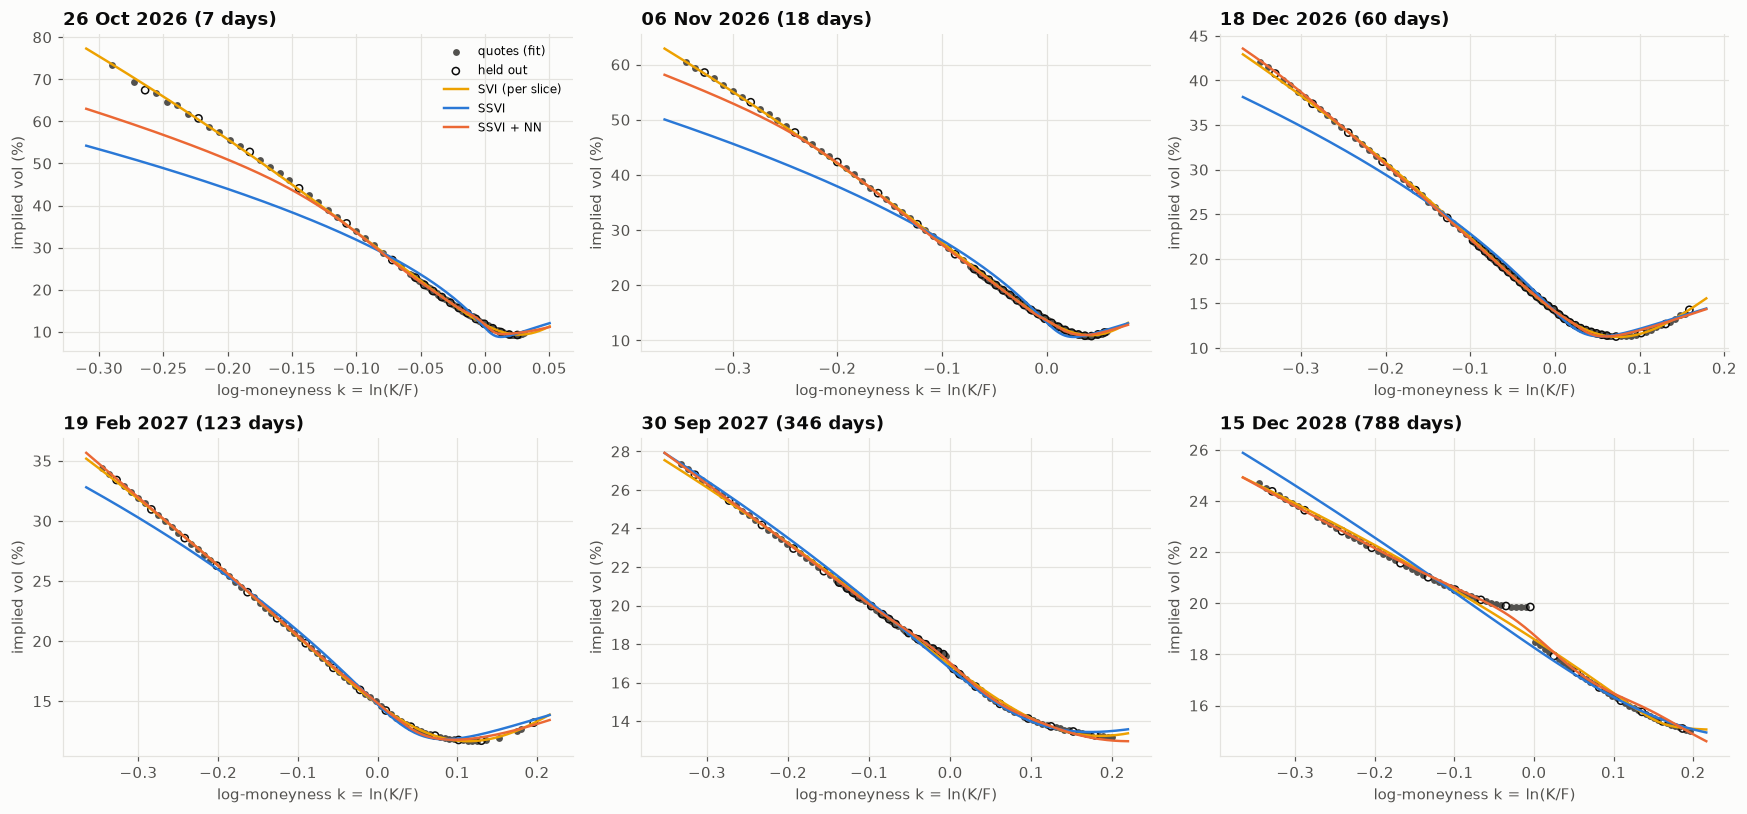

In [8]:
# --- Chart 1: smiles for six expiries
show = [
    EXPIRIES[i]
    for i in np.unique(
        np.linspace(0, len(EXPIRIES) - 1, 6).round().astype(int)
    )
]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, e in zip(axes.ravel(), show):
    g = opts[opts["expiry"] == e]
    T = g["T"].iloc[0]
    kline = np.linspace(g["k"].min() - 0.02, g["k"].max() + 0.02, 200)
    ax.scatter(
        g.loc[~g["holdout"], "k"],
        g.loc[~g["holdout"], "iv"] * 100,
        s=12,
        color=INK_2,
        label="quotes (fit)",
    )
    ax.scatter(
        g.loc[g["holdout"], "k"],
        g.loc[g["holdout"], "iv"] * 100,
        s=22,
        facecolors="none",
        edgecolors=INK,
        label="held out",
    )
    for name, color in MODEL_COLORS.items():
        ax.plot(
            kline,
            np.sqrt(model_w(name, kline, np.full_like(kline, T)) / T) * 100,
            color=color,
            lw=1.6,
            label=name,
        )
    ax.set_title(f"{pd.Timestamp(e):%d %b %Y} ({T * 365:.0f} days)")
    ax.set_xlabel("log-moneyness k = ln(K/F)")
    ax.set_ylabel("implied vol (%)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_smiles_by_expiry")
plt.show()

Local vol on the grid (median / 99th percentile / max, %): SSVI 27 / 94 / 107 · SSVI + NN 27 / 286 / 386


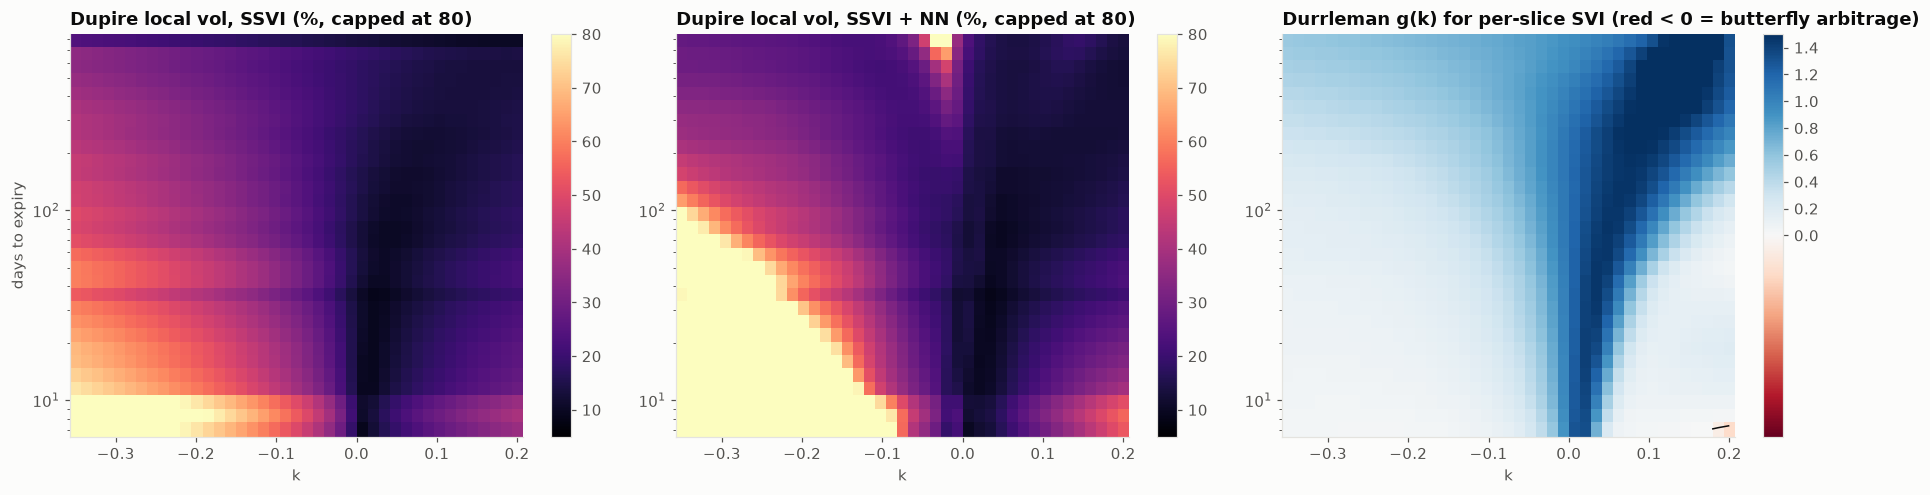

In [9]:
# --- Chart 2: local volatility from the two arbitrage-free surfaces, and the
# butterfly condition for SVI
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
k_ax, T_ax = np.linspace(*K_RANGE, 41), TT[:, 0]
local_vol = {}
for ax, name in zip(axes[:2], ["SSVI", "SSVI + NN"]):
    g_m, _ = g_numeric(name, kg, Tg)
    wT_m = (model_w(name, kg, Tg * 1.01) - model_w(name, kg, Tg * 0.99)) / (
        0.02 * Tg
    )
    lv = np.sqrt(np.clip(wT_m / g_m, 1e-8, None)).reshape(kk.shape) * 100
    local_vol[name] = lv
    im = ax.pcolormesh(
        k_ax, T_ax * 365, lv, cmap="magma", shading="auto", vmin=5, vmax=80
    )
    ax.set_title(f"Dupire local vol, {name} (%, capped at 80)")
    ax.set_yscale("log")
    ax.set_xlabel("k")
    plt.colorbar(im, ax=ax)
axes[0].set_ylabel("days to expiry")
print(
    "Local vol on the grid (median / 99th percentile / max, %): "
    + " · ".join(
        f"{n} {np.median(v):.0f} / {np.percentile(v, 99):.0f} / {v.max():.0f}"
        for n, v in local_vol.items()
    )
)
g_svi, _ = g_numeric("SVI (per slice)", kg, Tg)
im = axes[2].pcolormesh(
    k_ax,
    T_ax * 365,
    np.clip(g_svi.reshape(kk.shape), -0.05, 1.5),
    cmap="RdBu",
    shading="auto",
    norm=matplotlib.colors.TwoSlopeNorm(vmin=-0.05, vcenter=0.0, vmax=1.5),
)
axes[2].contour(
    k_ax,
    T_ax * 365,
    g_svi.reshape(kk.shape),
    levels=[0],
    colors=INK,
    linewidths=1,
)
axes[2].set_title(
    "Durrleman g(k) for per-slice SVI (red < 0 = butterfly arbitrage)"
)
axes[2].set_yscale("log")
axes[2].set_xlabel("k")
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
save_fig(fig, "02_surfaces_local_vol_arbitrage")
plt.show()
opts.to_csv(OUT_DIR / "spy_otm_quotes_iv.csv", index=False)
svi_tbl.to_csv(OUT_DIR / "svi_parameters_by_expiry.csv")
pd.DataFrame(
    {"T": T_OF.values, "theta_atm_total_var": THETA},
    index=[pd.Timestamp(e).date() for e in EXPIRIES],
).assign(rho=RHO, eta=ETA, gamma=GAMMA).to_csv(OUT_DIR / "ssvi_parameters.csv")
scorecard.to_csv(OUT_DIR / "surface_scorecard.csv")

## 8. Reading the results and limitations

SPY snapshot of 19 Oct 2026 (13 expiries from 7 days to 2.2 years, 1,767 OTM quotes):

**Per-slice SVI fits best (0.35 vol pts in sample, 0.23 on held-out strikes) but is not a surface.** Its slices cross: 14 calendar violations between consecutive expiries. It also has butterfly violations in the wings and **35 grid points where Dupire local variance is negative or undefined**. Feeding it to a local-vol or Monte Carlo engine would fail or produce free money.

**SSVI is arbitrage-free by construction** (minimum $g$ 0.25, no violations, clean local vol), with only 16 parameters, but it misses the short-dated skew. Its error is 2.5 vol points overall and 4.5 for expiries under a month, where SPY's put skew is far steeper than a single global ρ allows (at k = −0.3 the one-week quotes sit about 20 vol points above SSVI).

- **SSVI + neural correction gets most of the way back:** 0.9 vol points both in sample and on held-out strikes (1.8 under a month), with **zero violations** on the 1,230-point check grid. The hinge penalty with a small safety margin matters: a squared penalty left 11 small butterfly violations because it barely pushes on near-zero ones.

**Arbitrage-free is necessary, not sufficient.** The neural surface's local volatility has a ridge, up to almost 400%, in the short-dated put wing where the implied density is barely positive. Dupire divides by $g$, so a near-zero $g$ creates spikes. For local-vol pricing a production desk adds a curvature or density floor (a larger margin than 0.002) or smooths in local-vol space directly. For risk (Greeks, scenario repricing) the implied surface itself is what matters.

- **A data point worth flagging:** in the two-year expiry, puts just below the forward imply about 1.5 vol points more than calls just above it. That is the early-exercise premium of American SPY puts and the dividend uncertainty that a European put–call parity forward does not remove. Every model has to bridge that gap at $k=0$.

**Limitations**

- One snapshot: the surface is today's. Rerunning on another day gives another market, and an end-of-day snapshot is cleaner than an intraday one.
- American-style SPY options are treated as European. For OTM options with short lives the early-exercise premium is small, but it biases deep ITM-equivalent wings.
- The neural correction's arbitrage constraints are penalties, so they are enforced on the grid, not guaranteed everywhere. A production surface would check the final grid (as the scorecard does) and fall back to SSVI if any check fails.
- Local volatility is shown for diagnosis. Using it for pricing needs extrapolation in $k$ beyond the quoted range and a dividend model.

## References

### Finance and regulation

- Gatheral, J., & Jacquier, A. (2014). Arbitrage-free SVI volatility surfaces. *Quantitative Finance, 14*(1), 59–71. https://doi.org/10.1080/14697688.2013.819986
- Breeden, D. T., & Litzenberger, R. H. (1978). Prices of state-contingent claims implicit in option prices. *The Journal of Business, 51*(4), 621–651. https://doi.org/10.1086/296025
- Fengler, M. R. (2009). Arbitrage-free smoothing of the implied volatility surface. *Quantitative Finance, 9*(4), 417–428. https://doi.org/10.1080/14697680802595585

### Machine learning and deep learning

- Ackerer, D., Tagasovska, N., & Vatter, T. (2020). Deep smoothing of the implied volatility surface. *Advances in Neural Information Processing Systems, 33*. https://arxiv.org/abs/1906.05065
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703
- Baydin, A. G., Pearlmutter, B. A., Radul, A. A., & Siskind, J. M. (2018). Automatic differentiation in machine learning: A survey. *Journal of Machine Learning Research, 18*(153), 1–43. https://jmlr.org/papers/v18/17-468.html